# Inferência da ResNet18 no Fashion-MNIST: *trade-off* e escolha do *batch size*

Notebook com os experimentos do artigo **"Inferência da ResNet18 no Fashion-MNIST: modelagem do *trade-off* e otimização do *batch size* sob a perspectiva da Pesquisa Operacional"**, apresentado no SBPO 2026.

**Autores:** Hugo César Leal, Andressa Caroline Lopes de Assis, Sadi Martins de Castro Garcia Mendes, Ciniro Aparecido Leite Nametala, Marcos Roberto Ribeiro e Bruno Alberto Soares Oliveira
IFMG – Campus Bambuí · Grupo de Pesquisa em Sistemas Computacionais (GPSisCom)

---

No trabalho, o *batch size* é tratado como variável de decisão: queremos saber qual tamanho de lote dá o melhor retorno em tempo e *throughput* sem estourar a memória do dispositivo. Para isso, a ResNet18 pré-treinada no ImageNet faz a inferência sobre as 10.000 imagens de teste do Fashion-MNIST, em CPU e em GPU, e medimos:

- tempo total de inferência;
- *throughput* (imagens/s);
- *speedup* em relação ao *baseline* sequencial (CPU, lote 1);
- eficiência paralela (*speedup* / *batch size*);
- fração sequencial estimada pela Lei de Amdahl.

Cada configuração é executada 5 vezes e os resultados são resumidos por média e desvio padrão.

### Ambientes

O mesmo notebook foi rodado nos quatro ambientes abaixo. **As saídas salvas aqui são da execução no Google Colab.**

| Ambiente | CPU | GPU | VRAM | RAM |
|---|---|---|---|---|
| Google Colab | Intel Xeon @ 2.00GHz (2 vCPUs) | Tesla T4 | 16 GB | 12 GB |
| Máquina Local 1 | AMD Ryzen 7 5800H | GeForce GTX 1650 | 4 GB | 16 GB |
| Máquina Local 2 | AMD Ryzen 5 5500 | GeForce RTX 3060 | 8 GB | 32 GB |
| Máquina Local 3 | AMD Ryzen 5 5600 | GeForce RTX 4060 | 8 GB | 16 GB |

### Como executar

- **Colab:** *Ambiente de execução → Alterar o tipo de ambiente de execução → GPU (T4)* e depois *Executar tudo*.
- **Local:** Python 3 com `torch`, `torchvision`, `numpy`, `pandas` e `matplotlib` (PyTorch com suporte a CUDA para a parte em GPU). As duas últimas células usam `nvidia-smi` e `lscpu`, que só existem em Linux.

A parte em CPU é a que mais demora. No Colab, cada repetição do *baseline* levou perto de 10 minutos.

Arquivos gerados: `resultados_inferencia.csv` e os gráficos `grafico_*_vs_batch.png` de cada ambiente. Os gráficos consolidados do artigo (os quatro ambientes na mesma figura) e o ajuste de $S$ por mínimos quadrados foram feitos depois, a partir dos CSVs de cada máquina, e não fazem parte deste notebook.

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torchvision
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

## 1. Configurações do experimento

Parâmetros fixos: semente, número de repetições e os lotes testados em cada dispositivo.

As grades de CPU e GPU são diferentes de propósito. Na CPU, lotes grandes acrescentam pouco paralelismo útil e só aumentam o custo de processamento e memória, por isso ficamos em 8, 32 e 64. Na GPU, lotes maiores são justamente o que aumenta a ocupação do acelerador, então a grade vai de 1 até 512 (respeitando a memória de cada placa).

Repetimos cada teste porque o tempo varia de uma execução para outra, principalmente no Colab, que é um ambiente compartilhado.

In [ ]:
SEED = 42
NUM_REPETICOES = 5

# Lotes avaliados em cada dispositivo
CPU_BATCHES = [8, 32, 64]
GPU_BATCHES = [1, 8, 32, 64, 128, 256, 512]

# Mesmo valor do baseline sequencial
NUM_WORKERS = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device_gpu = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"GPU disponível: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Nome da GPU: {torch.cuda.get_device_name(0)}")

GPU disponível: True
Nome da GPU: Tesla T4


## 2. Dataset

Usamos apenas o conjunto de teste do Fashion-MNIST: 10.000 imagens $28 \times 28$ em tons de cinza, 10 classes.

A ResNet18 foi pré-treinada no ImageNet, com imagens RGB maiores, então as imagens passam por:

1. redimensionamento para $224 \times 224$;
2. conversão para tensor;
3. replicação do canal único para 3 canais;
4. normalização com média e desvio padrão do ImageNet.

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    # Fashion-MNIST tem 1 canal; a ResNet18 espera 3
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    # Estatísticas do ImageNet
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Apenas o conjunto de teste (10.000 imagens)
test_set = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print(f"Quantidade de imagens no conjunto de teste: {len(test_set)}")

Quantidade de imagens no conjunto de teste: 10000


## 3. Modelo

ResNet18 com os pesos pré-treinados do ImageNet (`ResNet18_Weights.DEFAULT`), em modo `eval()`. Como só medimos inferência, não há atualização de parâmetros e o *batch normalization* usa as estatísticas já aprendidas.

In [ ]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)
model.eval()

print("Modelo ResNet18 carregado com sucesso.")

Modelo ResNet18 carregado com sucesso.


## 4. Funções auxiliares

- `criar_dataloader`: monta o `DataLoader` com o lote desejado (sem embaralhar);
- `medir_inferencia`: percorre o conjunto de teste inteiro e devolve tempo total e *throughput*;
- `executar_repeticoes`: repete a medição e calcula média e desvio padrão;
- `calcular_fracao_sequencial`: isola $S$ na Lei de Amdahl.

Em GPU, as operações CUDA são assíncronas. Por isso há `torch.cuda.synchronize()` antes de iniciar e antes de parar o cronômetro; sem isso o tempo medido sai menor do que o real. Também é feito um *warm-up* com um lote antes da medição, para que a inicialização do CUDA não entre na conta.

In [ ]:
def criar_dataloader(dataset, batch_size, use_gpu=False, num_workers=0):
    """DataLoader sem embaralhamento; pin_memory só quando os dados vão para a GPU."""
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=use_gpu
    )


def medir_inferencia(modelo, dataloader, dispositivo):
    """Roda a inferência em todo o dataloader e retorna (tempo_total, throughput)."""
    modelo.to(dispositivo)
    modelo.eval()

    # Warm-up: um lote antes de medir, para tirar o custo de inicialização do CUDA
    if dispositivo.type == "cuda":
        with torch.no_grad():
            for imagens, _ in dataloader:
                imagens = imagens.to(dispositivo, non_blocking=True)
                _ = modelo(imagens)
                break
        torch.cuda.synchronize()

    if dispositivo.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.time()

    with torch.no_grad():
        for imagens, _ in dataloader:
            imagens = imagens.to(dispositivo, non_blocking=True)
            _ = modelo(imagens)

    # CUDA é assíncrono: espera a GPU terminar antes de parar o cronômetro
    if dispositivo.type == "cuda":
        torch.cuda.synchronize()

    fim = time.time()

    tempo_total = fim - inicio
    throughput = len(dataloader.dataset) / tempo_total

    return tempo_total, throughput


def executar_repeticoes(modelo, dataset, batch_size, hardware, repeticoes=5, num_workers=0):
    """
    Repete a medição `repeticoes` vezes em 'CPU' ou 'GPU' e devolve média e
    desvio padrão (amostral) do tempo e do throughput.
    Retorna None se hardware='GPU' e não houver CUDA.
    """
    if hardware == "CPU":
        dispositivo = torch.device("cpu")
        use_gpu = False
    elif hardware == "GPU":
        if not torch.cuda.is_available():
            return None
        dispositivo = torch.device("cuda")
        use_gpu = True
    else:
        raise ValueError("hardware deve ser 'CPU' ou 'GPU'")

    tempos = []
    throughputs = []

    for repeticao in range(repeticoes):
        loader = criar_dataloader(
            dataset=dataset,
            batch_size=batch_size,
            use_gpu=use_gpu,
            num_workers=num_workers
        )

        tempo_total, throughput = medir_inferencia(modelo, loader, dispositivo)

        tempos.append(tempo_total)
        throughputs.append(throughput)

        print(
            f"[{hardware}] batch={batch_size} | repetição {repeticao + 1}/{repeticoes} "
            f"| tempo={tempo_total:.4f}s | throughput={throughput:.2f} img/s"
        )

    return {
        "tempo_medio": float(np.mean(tempos)),
        "tempo_std": float(np.std(tempos, ddof=1)) if len(tempos) > 1 else 0.0,
        "throughput_medio": float(np.mean(throughputs)),
        "throughput_std": float(np.std(throughputs, ddof=1)) if len(throughputs) > 1 else 0.0,
    }


def calcular_fracao_sequencial(speedup_real, n):
    """
    Fração sequencial S pela Lei de Amdahl, Speedup <= 1 / (S + (1-S)/N):
        S = (1/speedup - 1/N) / (1 - 1/N)
    """
    if n <= 1 or speedup_real <= 1:
        return None

    valor = (1 / speedup_real - 1 / n) / (1 - 1 / n)
    return valor

## 5. *Baseline* sequencial

Referência para o cálculo do *speedup*: **CPU, *batch size* = 1 e `num_workers` = 0**, ou seja, uma imagem por vez, sem paralelismo de dados.

In [ ]:
print("\n=== BASELINE: CPU, batch_size=1, num_workers=0 ===")

baseline = executar_repeticoes(
    modelo=model,
    dataset=test_set,
    batch_size=1,
    hardware="CPU",
    repeticoes=NUM_REPETICOES,
    num_workers=0
)

tempo_baseline = baseline["tempo_medio"]
throughput_baseline = baseline["throughput_medio"]

print("\nBaseline concluído:")
print(f"Tempo médio: {tempo_baseline:.4f}s")
print(f"Desvio do tempo: {baseline['tempo_std']:.4f}s")
print(f"Throughput médio: {throughput_baseline:.2f} img/s")
print(f"Desvio do throughput: {baseline['throughput_std']:.2f} img/s")


=== BASELINE: CPU, batch_size=1, num_workers=0 ===
[CPU] batch=1 | repetição 1/5 | tempo=590.9573s | throughput=16.92 img/s
[CPU] batch=1 | repetição 2/5 | tempo=612.5817s | throughput=16.32 img/s
[CPU] batch=1 | repetição 3/5 | tempo=592.3372s | throughput=16.88 img/s
[CPU] batch=1 | repetição 4/5 | tempo=585.2421s | throughput=17.09 img/s
[CPU] batch=1 | repetição 5/5 | tempo=592.3321s | throughput=16.88 img/s

Baseline concluído:
Tempo médio: 594.6901s
Desvio do tempo: 10.4212s
Throughput médio: 16.82 img/s
Desvio do throughput: 0.29 img/s


## 6. Experimentos em CPU e GPU

Para cada lote são registrados tempo médio, *throughput* médio e os respectivos desvios. A partir deles:

- *speedup* = tempo do *baseline* / tempo da configuração;
- eficiência = *speedup* / *batch size*, usando o lote como aproximação do grau de paralelismo $N$ (calculada só para GPU).

Se algum lote não couber na memória da GPU, a configuração é pulada e o experimento continua.

In [ ]:
resultados = []

resultados.append({
    "Configuração": "CPU",
    "Batch Size": 1,
    "Tempo Médio (s)": baseline["tempo_medio"],
    "Desvio Tempo (s)": baseline["tempo_std"],
    "Throughput Médio (img/s)": baseline["throughput_medio"],
    "Desvio Throughput": baseline["throughput_std"],
    "Speedup": 1.0,
    "Eficiência": np.nan
})

# ---- CPU ----
print("\n=== EXPERIMENTOS EM CPU ===")

for bs in CPU_BATCHES:
    resultado = executar_repeticoes(
        modelo=model,
        dataset=test_set,
        batch_size=bs,
        hardware="CPU",
        repeticoes=NUM_REPETICOES,
        num_workers=NUM_WORKERS
    )

    speedup = tempo_baseline / resultado["tempo_medio"]

    resultados.append({
        "Configuração": "CPU",
        "Batch Size": bs,
        "Tempo Médio (s)": resultado["tempo_medio"],
        "Desvio Tempo (s)": resultado["tempo_std"],
        "Throughput Médio (img/s)": resultado["throughput_medio"],
        "Desvio Throughput": resultado["throughput_std"],
        "Speedup": speedup,
        "Eficiência": np.nan
    })

# ---- GPU ----
if torch.cuda.is_available():
    print("\n=== EXPERIMENTOS EM GPU ===")

    for bs in GPU_BATCHES:
        try:
            resultado = executar_repeticoes(
                modelo=model,
                dataset=test_set,
                batch_size=bs,
                hardware="GPU",
                repeticoes=NUM_REPETICOES,
                num_workers=NUM_WORKERS
            )

            speedup = tempo_baseline / resultado["tempo_medio"]

            # batch size como aproximação do grau de paralelismo N
            eficiencia = speedup / bs

            resultados.append({
                "Configuração": "GPU",
                "Batch Size": bs,
                "Tempo Médio (s)": resultado["tempo_medio"],
                "Desvio Tempo (s)": resultado["tempo_std"],
                "Throughput Médio (img/s)": resultado["throughput_medio"],
                "Desvio Throughput": resultado["throughput_std"],
                "Speedup": speedup,
                "Eficiência": eficiencia
            })

        except RuntimeError as e:
            # Lote maior que a memória da GPU: pula e segue para o próximo
            if "out of memory" in str(e).lower():
                print(f"Batch size {bs} excedeu a memória da GPU. Pulando essa configuração.")
                torch.cuda.empty_cache()
            else:
                raise e

df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    by=["Configuração", "Batch Size"]
).reset_index(drop=True)


=== EXPERIMENTOS EM CPU ===
[CPU] batch=8 | repetição 1/5 | tempo=487.6262s | throughput=20.51 img/s
[CPU] batch=8 | repetição 2/5 | tempo=491.0414s | throughput=20.36 img/s
[CPU] batch=8 | repetição 3/5 | tempo=493.4586s | throughput=20.27 img/s
[CPU] batch=8 | repetição 4/5 | tempo=483.8400s | throughput=20.67 img/s
[CPU] batch=8 | repetição 5/5 | tempo=491.7202s | throughput=20.34 img/s
[CPU] batch=32 | repetição 1/5 | tempo=552.3193s | throughput=18.11 img/s
[CPU] batch=32 | repetição 2/5 | tempo=548.4217s | throughput=18.23 img/s
[CPU] batch=32 | repetição 3/5 | tempo=550.0446s | throughput=18.18 img/s
[CPU] batch=32 | repetição 4/5 | tempo=550.1968s | throughput=18.18 img/s
[CPU] batch=32 | repetição 5/5 | tempo=545.4731s | throughput=18.33 img/s
[CPU] batch=64 | repetição 1/5 | tempo=605.5801s | throughput=16.51 img/s
[CPU] batch=64 | repetição 2/5 | tempo=606.1448s | throughput=16.50 img/s
[CPU] batch=64 | repetição 3/5 | tempo=592.7213s | throughput=16.87 img/s
[CPU] batch=64

## 7. Tabela de resultados

Tabela com todas as configurações. O mesmo conteúdo é salvo em `resultados_inferencia.csv`, que foi usado para montar as tabelas do artigo.

In [ ]:
print("\n=== TABELA FINAL DOS RESULTADOS ===")
display(df_resultados)

df_resultados.to_csv("resultados_inferencia.csv", index=False)

print("Arquivo salvo: resultados_inferencia.csv")


=== TABELA FINAL DOS RESULTADOS ===


,Configuração,Batch Size,Tempo Médio (s),Desvio Tempo (s),Throughput Médio (img/s),Desvio Throughput,Speedup,Eficiência
0,CPU,1,594.690083,10.421206,16.819538,0.289415,1.000000,NaN
1,CPU,8,489.537283,3.824779,20.428455,0.160275,1.214800,NaN
2,CPU,32,549.291099,2.544135,18.205596,0.084487,1.082650,NaN
3,CPU,64,599.602558,6.387586,16.679229,0.177796,0.991807,NaN
4,GPU,1,35.689773,0.249561,280.203218,1.950074,16.662759,16.662759
5,GPU,8,13.703616,0.467736,730.406343,24.610400,43.396581,5.424573
6,GPU,32,11.874957,0.110574,842.166544,7.815287,50.079347,1.564980
7,GPU,64,13.993965,0.125853,714.640004,6.428010,42.496182,0.664003
8,GPU,128,14.199420,0.210401,704.376363,10.312794,41.881294,0.327198
9,GPU,256,15.115082,0.162326,661.651929,7.108113,39.344152,0.153688


Arquivo salvo: resultados_inferencia.csv


## 8. Gráficos

Gráficos deste ambiente (as barras de erro são o desvio padrão das 5 repetições):

1. *throughput* × *batch size*;
2. tempo total × *batch size*;
3. *speedup* × *batch size*, com a reta do *speedup* ideal ($\text{speedup} = N$);
4. eficiência paralela × *batch size*.

In [ ]:
cpu_res = df_resultados[df_resultados["Configuração"] == "CPU"].copy()
gpu_res = df_resultados[df_resultados["Configuração"] == "GPU"].copy()

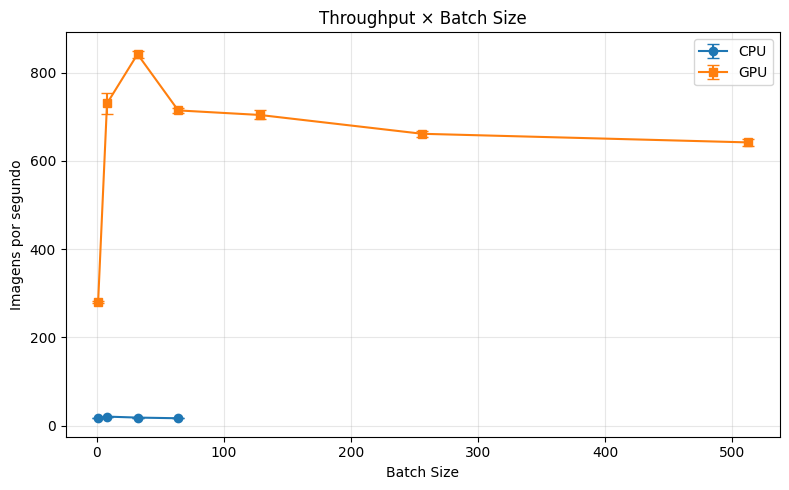

In [ ]:
# Throughput x batch size

plt.figure(figsize=(8, 5))

plt.errorbar(
    cpu_res["Batch Size"],
    cpu_res["Throughput Médio (img/s)"],
    yerr=cpu_res["Desvio Throughput"],
    marker="o",
    capsize=4,
    label="CPU"
)

if not gpu_res.empty:
    plt.errorbar(
        gpu_res["Batch Size"],
        gpu_res["Throughput Médio (img/s)"],
        yerr=gpu_res["Desvio Throughput"],
        marker="s",
        capsize=4,
        label="GPU"
    )

plt.title("Throughput × Batch Size")
plt.xlabel("Batch Size")
plt.ylabel("Imagens por segundo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("grafico_throughput_vs_batch.png", dpi=300)
plt.show()

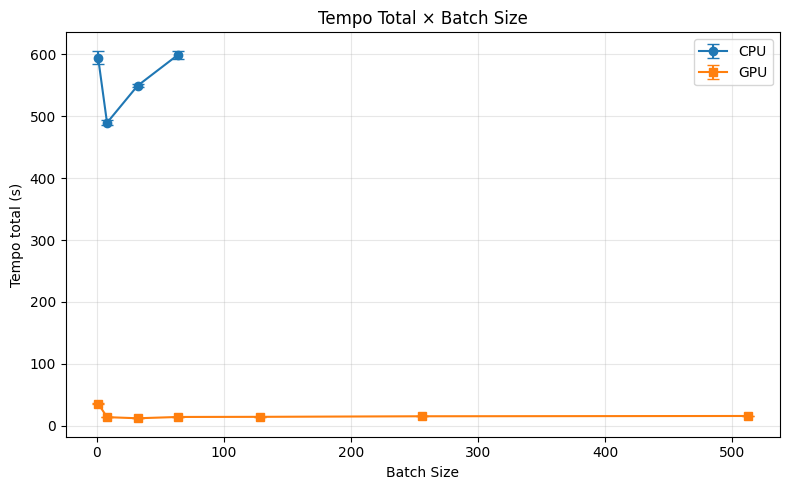

In [ ]:
# Tempo total x batch size

plt.figure(figsize=(8, 5))

plt.errorbar(
    cpu_res["Batch Size"],
    cpu_res["Tempo Médio (s)"],
    yerr=cpu_res["Desvio Tempo (s)"],
    marker="o",
    capsize=4,
    label="CPU"
)

if not gpu_res.empty:
    plt.errorbar(
        gpu_res["Batch Size"],
        gpu_res["Tempo Médio (s)"],
        yerr=gpu_res["Desvio Tempo (s)"],
        marker="s",
        capsize=4,
        label="GPU"
    )

plt.title("Tempo Total × Batch Size")
plt.xlabel("Batch Size")
plt.ylabel("Tempo total (s)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("grafico_tempo_vs_batch.png", dpi=300)
plt.show()

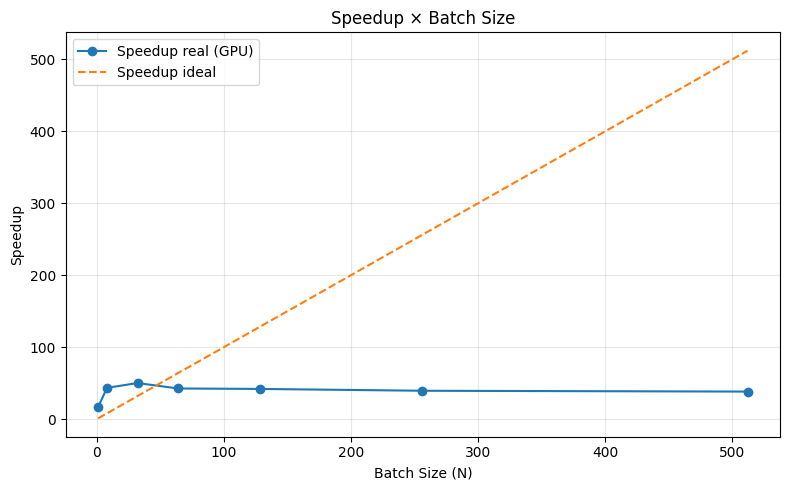

In [ ]:
# Speedup x batch size

if not gpu_res.empty:
    plt.figure(figsize=(8, 5))

    plt.plot(
        gpu_res["Batch Size"],
        gpu_res["Speedup"],
        marker="o",
        label="Speedup real (GPU)"
    )

    # Speedup ideal: speedup = N
    plt.plot(
        gpu_res["Batch Size"],
        gpu_res["Batch Size"],
        linestyle="--",
        label="Speedup ideal"
    )

    plt.title("Speedup × Batch Size")
    plt.xlabel("Batch Size (N)")
    plt.ylabel("Speedup")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("grafico_speedup_vs_batch.png", dpi=300)
    plt.show()

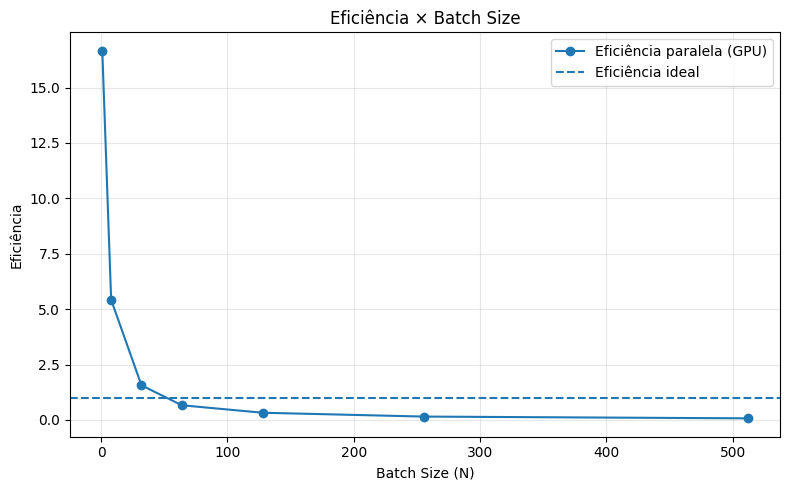

In [ ]:
# Eficiência x batch size

if not gpu_res.empty:
    plt.figure(figsize=(8, 5))

    plt.plot(
        gpu_res["Batch Size"],
        gpu_res["Eficiência"],
        marker="o",
        label="Eficiência paralela (GPU)"
    )

    plt.axhline(1.0, linestyle="--", label="Eficiência ideal")

    plt.title("Eficiência × Batch Size")
    plt.xlabel("Batch Size (N)")
    plt.ylabel("Eficiência")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("grafico_eficiencia_vs_batch.png", dpi=300)
    plt.show()

## 9. Fração sequencial (Lei de Amdahl)

$$\text{Speedup} \leq \frac{1}{S + \frac{1-S}{N}} \quad\Rightarrow\quad S = \frac{1/\text{Speedup} - 1/N}{1 - 1/N}$$

Aqui $S$ é calculado a partir do maior *speedup* observado em GPU, com $N$ igual ao *batch size* correspondente. $S$ representa a parcela do tempo que não se beneficia do paralelismo: transferência CPU → GPU, *overhead* do framework, pré-processamento das imagens, sincronização etc.

**Atenção:** esse *speedup* é medido contra o *baseline* em CPU, então mistura o ganho do lote com a diferença de hardware entre CPU e GPU. No Colab, por exemplo, o *speedup* de 50,08 com lote 32 passa do limite que Amdahl permitiria para $N = 32$, e o $S$ resultante sai negativo. Por esse motivo, os valores de $S$ reportados no artigo (≈ 0,38 no Colab, 0,42, 0,16 e 0,15 nas máquinas locais) foram estimados de outra forma: com o *speedup* intra-GPU (tempo com lote 1 / tempo com lote $b$), ajustado por mínimos quadrados em cada ambiente.

In [ ]:
if not gpu_res.empty:
    # Configuração com maior speedup em GPU
    idx_max_speedup = gpu_res["Speedup"].idxmax()
    melhor_gpu = gpu_res.loc[idx_max_speedup]

    n_melhor = int(melhor_gpu["Batch Size"])
    speedup_melhor = float(melhor_gpu["Speedup"])

    fracao_sequencial = calcular_fracao_sequencial(speedup_melhor, n_melhor)

    print("\n=== ANÁLISE PELA LEI DE AMDAHL ===")
    print(f"Maior speedup real observado: {speedup_melhor:.4f}")
    print(f"Batch size correspondente: {n_melhor}")

    if fracao_sequencial is not None:
        print(f"Fração sequencial estimada S: {fracao_sequencial:.6f}")
        print(f"Percentual sequencial estimado: {fracao_sequencial * 100:.2f}%")
    else:
        print("Não foi possível estimar a fração sequencial.")


=== ANÁLISE PELA LEI DE AMDAHL ===
Maior speedup real observado: 50.0793
Batch size correspondente: 32
Fração sequencial estimada S: -0.011646
Percentual sequencial estimado: -1.16%


## 10. Resumo

Versão enxuta da tabela, só com as métricas principais.

Na execução do Colab salva neste notebook, o melhor lote em GPU foi **32**: 11,87 s, 842,17 img/s e *speedup* de 50,08. A partir de 64 o *throughput* cai e o tempo volta a subir, que é o comportamento de retornos decrescentes discutido no artigo. Em CPU o melhor foi o lote 8 (20,43 img/s), um ganho pequeno sobre o *baseline*.

In [ ]:
colunas_resumo = [
    "Configuração",
    "Batch Size",
    "Tempo Médio (s)",
    "Throughput Médio (img/s)",
    "Speedup",
    "Eficiência"
]

print("\n=== RESUMO DOS RESULTADOS ===")
print(df_resultados[colunas_resumo].to_string(index=False))


=== RESUMO DOS RESULTADOS ===
Configuração  Batch Size  Tempo Médio (s)  Throughput Médio (img/s)   Speedup  Eficiência
         CPU           1       594.690083                 16.819538  1.000000         NaN
         CPU           8       489.537283                 20.428455  1.214800         NaN
         CPU          32       549.291099                 18.205596  1.082650         NaN
         CPU          64       599.602558                 16.679229  0.991807         NaN
         GPU           1        35.689773                280.203218 16.662759   16.662759
         GPU           8        13.703616                730.406343 43.396581    5.424573
         GPU          32        11.874957                842.166544 50.079347    1.564980
         GPU          64        13.993965                714.640004 42.496182    0.664003
         GPU         128        14.199420                704.376363 41.881294    0.327198
         GPU         256        15.115082                661.651929 3

## 11. Informações do ambiente

Registro da GPU e da CPU usadas na execução (saída do Colab).

In [ ]:
!nvidia-smi

Sun Apr 19 18:38:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   73C    P0             30W /   70W |    9833MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!lscpu

Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             46 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      2
  On-line CPU(s) list:       0,1
Vendor ID:                   GenuineIntel
  Model name:                Intel(R) Xeon(R) CPU @ 2.00GHz
    CPU family:              6
    Model:                   85
    Thread(s) per core:      2
    Core(s) per socket:      1
    Socket(s):               1
    Stepping:                3
    BogoMIPS:                4000.35
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ss h
                             t syscall nx pdpe1gb rdtscp lm constant_tsc rep_goo
                             d nopl xtopology nonstop_tsc cpuid tsc_known_freq p
                             ni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2ap
                   